In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

f = pd.read_parquet("data/clean/features.parquet")
num = ["amt", "amt_vs_usual", "txn_last_1h", "txn_last_24h", "spend_last_24h", "secs_since_prev",
       "new_merchant", "new_category", "distance_km", "age", "is_night", "hour"]
X = pd.get_dummies(f[num + ["category", "gender"]], columns=["category", "gender"], drop_first=True, dtype=int)
y = f["is_fraud"]
tr, va, te = (f["period"] == "train"), (f["period"] == "valid"), (f["period"] == "test")
print("Features:", X.shape[1], "| train:", tr.sum(), "| valid:", va.sum(), "| test:", te.sum())

Features: 26 | train: 924850 | valid: 401883 | test: 525661


In [2]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42),
}
for name, m in models.items():
    m.fit(X[tr], y[tr])
    print(f"{name} trained ✅")

Logistic regression trained ✅
Gradient boosting trained ✅


In [3]:
def fraud_caught_at(y_true, score, pct):
    """If analysts review the top pct% riskiest transactions, what share of fraud is caught,
    and what share of alerts are real fraud?"""
    k = int(len(score) * pct / 100)
    top = np.argsort(-score)[:k]
    caught = y_true.iloc[top].sum()
    return caught / y_true.sum() * 100, caught / k * 100

rows = []
for name, m in models.items():
    s = m.predict_proba(X[va])[:, 1]
    row = {"model": name,
           "ROC_AUC": roc_auc_score(y[va], s),
           "PR_AUC": average_precision_score(y[va], s)}
    for pct in [0.5, 1, 2]:
        rec, prec = fraud_caught_at(y[va], s, pct)
        row[f"fraud_caught_top{pct}%"] = rec
        row[f"alerts_that_are_fraud_top{pct}%"] = prec
    rows.append(row)
pd.DataFrame(rows).round(3).T

,0,1
model,Logistic regression,Gradient boosting
ROC_AUC,0.965,0.975
PR_AUC,0.557,0.888
fraud_caught_top0.5%,58.082,76.767
alerts_that_are_fraud_top0.5%,69.935,92.434
fraud_caught_top1%,70.277,91.98
alerts_that_are_fraud_top1%,42.31,55.376
fraud_caught_top2%,76.933,93.468
alerts_that_are_fraud_top2%,23.155,28.132


In [4]:
import os, joblib
best = models["Gradient boosting"]
cols = ["trans_num", "ts", "cc_num", "category", "amt", "age", "is_fraud", "period",
        "amt_vs_usual", "txn_last_1h", "txn_last_24h", "spend_last_24h", "secs_since_prev", "is_night", "new_merchant"]
scored = f.loc[va | te, cols].copy()
scored["score"] = best.predict_proba(X[va | te])[:, 1]
scored.to_parquet("data/clean/scores.parquet", index=False)
joblib.dump(best, "data/clean/model_gb.joblib")
print(scored["period"].value_counts())

period
test     525661
valid    401883
Name: count, dtype: int64


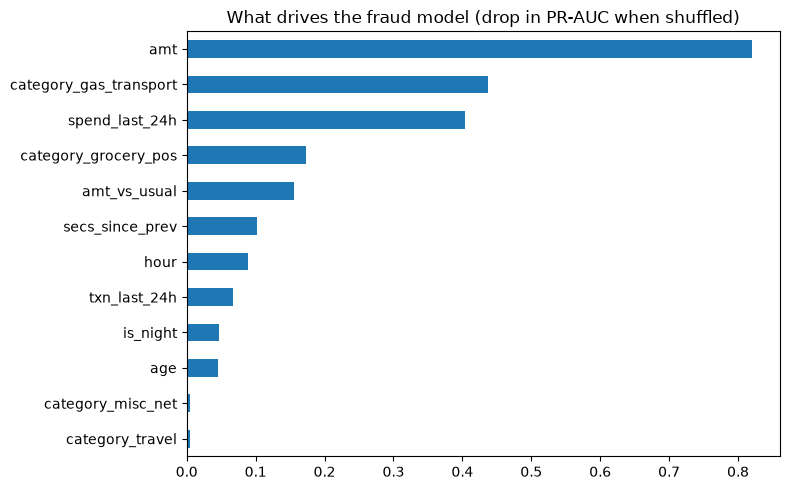

amt                       0.820
category_gas_transport    0.438
spend_last_24h            0.404
category_grocery_pos      0.172
amt_vs_usual              0.156
secs_since_prev           0.102
hour                      0.089
txn_last_24h              0.067
is_night                  0.047
age                       0.045
category_misc_net         0.005
category_travel           0.005
dtype: float64

In [5]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

sample = X[va].sample(100_000, random_state=42)
pi = permutation_importance(best, sample, y.loc[sample.index], scoring="average_precision",
                            n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=sample.columns).sort_values(ascending=False).head(12)

os.makedirs("outputs", exist_ok=True)
imp.sort_values().plot.barh(figsize=(8, 5), title="What drives the fraud model (drop in PR-AUC when shuffled)")
plt.tight_layout(); plt.savefig("outputs/feature_importance.png", dpi=150); plt.show()
imp.round(3)